## Task 1

In [1]:
class Person():
    def __init__(self,name : str,age : int):
        self.name = name
        self.age = age
    def display(self):
        print('Name : ',self.name)
        print('Age : ',self.age)

class Student(Person):
    def __init__(self,name : str, age:int):
        super().__init__(name,age)
    def display_role(self):
        print('Student')
        super().display()
        
class Teacher(Person):
    def __init__(self,name : str,age:int):
        super().__init__(name,age)
    def display_role(self):
        print('Teacher')
        super().display()
        
class Principal(Person):
    def __init__(self, name:str, age:int):
        super().__init__(name,age)
    def display_role(self):
        print('Principal')
        super().display()

student = Student('Rahul',13)
teacher = Teacher('Dhamu',34)
principal = Principal('Gumo',65)

student.display_role()
teacher.display_role()
principal.display_role()

Student
Name :  Rahul
Age :  13
Teacher
Name :  Dhamu
Age :  34
Principal
Name :  Gumo
Age :  65


## Task 2

In [2]:
import numpy as np
from scipy import stats
wfh = [78, 82, 85, 80, 76, 88, 90]
wfo = [72, 75, 79, 81, 70, 77, 74]
result = stats.ttest_ind(wfh,wfo,equal_var = False)
print('t-value : ',result.statistic)
print('p-value : ',result.pvalue)
alpha = .05

if result.pvalue < .05:
    print('Rejected H0')
    print('WFO and WFH is Independet features')
else:
    print('Failed to Reject H1')

t-value :  2.979451812968625
p-value :  0.012423490746205013
Rejected H0
WFO and WFH is Independet features


## Task 3

### connects python to MYSQL

In [3]:
import mysql.connector as sql

db = sql.connect(
    host = 'localhost',
    user = 'root',
    password = '9048'
)

cmd = db.cursor()

In [4]:
cmd.execute('SHOW DATABASES;')
for database in cmd.fetchall():
    print(database[0])

information_schema
mydatabase
mysql
performance_schema
spectrum
sys
test
zarko


In [5]:
cmd.execute('CREATE DATABASE SPECTRUM')
print(cmd.fetchall())

DatabaseError: 1007 (HY000): Can't create database 'spectrum'; database exists

In [ ]:
cmd.execute('USE SPECTRUM')
print(cmd.fetchall())

In [ ]:
cmd.execute("""
CREATE TABLE employees (
    emp_id INT PRIMARY KEY,
    name VARCHAR(50) NOT NULL,
    department VARCHAR(50),
    salary INT
)
""")
print(cmd.fetchall())

In [ ]:
cmd.execute("""
INSERT INTO employees
VALUES (1,'AROMAL','IT','50000'),
    (2,'GOUMA','MANAGER','100000'),
    (3,'YART','MARKETING',35000),
    (4,'TIARA','IT',40000),
    (5,'HELTA','MARKETING',46000),
    (6,'JACOB','SUPPORT',30000)""")
print(cmd.fetchall())

### Displays all Employees

In [ ]:
cmd.execute('SELECT * FROM employees')
for i in cmd.fetchall():
    print(i)

### Adds a New Employee

In [ ]:
cmd.execute("""
INSERT INTO employees
VALUES (7,'NETHER','IT','75000')
""")
print(cmd.fetchall())

In [ ]:
cmd.execute('SELECT * FROM employees')
for i in cmd.fetchall():
    print(i)

### Update an Employees Salary

In [ ]:
cmd.execute("""
UPDATE employees
SET salary = 50000
WHERE emp_id = 7
""")
print(cmd.fetchall())

### Delete an Employee

In [ ]:
cmd.execute("""
DELETE FROM employees
WHERE emp_id = '4'
""")
print(cmd.fetchall())

### Displays employees whose salary is greater than ₹50,000.

In [ ]:
cmd.execute("""
SELECT *
FROM employees
WHERE salary > 50000;
""")
print(cmd.fetchall())

## Task 4

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [7]:
df = {
    'Order_ID' : [4356,8574,5232,4582,7597,4316,6759,7256,5849,2914,6733],
    'Date' : ['2024-03-01','2024-04-01','2024-05-01','2024-06-01','2024-03-04','2024-07-01','2024-08-01','2024-09-01','2024-10-01','2024-11-01','2024-12-01'],
    'Product' : ['RTX-4050','RTX-4050','RTX-4050','RTX-5050','RTX-3050','RTX-2040','RTX-3050','RTX-3050','RTX-4050','RTX-3050','RTX-3040'],
    'Category' : ['Video','Video','Gaming','Gaming','Gaming','AI','Cloud','Gaming','Gaming','Video','Video'],
    'Sales' : [106999,106999,106999,55499,34999,25000,34999,34999,106999,34999,30000],
    'Quantity' : [1,1,2,2,1,3,2,1,3,2,1],
    'City' : ['Thrissur','Thrissur','Kottayam','Ernakulam','Kollam','Trivandrum','Kazhargod','Kannur','Palakad','Malapuram','Thrissur']
}

data = pd.DataFrame(df)

In [8]:
data['Date'] = pd.to_datetime(data['Date'])

In [9]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  11 non-null     int64         
 1   Date      11 non-null     datetime64[us]
 2   Product   11 non-null     str           
 3   Category  11 non-null     str           
 4   Sales     11 non-null     int64         
 5   Quantity  11 non-null     int64         
 6   City      11 non-null     str           
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 748.0 bytes


### Which chart would you use to show monthly sales trends?

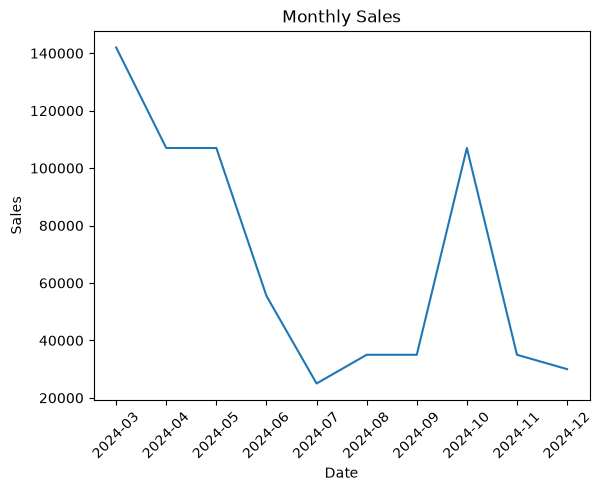

In [13]:
monthly_sales = data.groupby(
    data['Date'].dt.to_period('M')
)['Sales'].sum()
sns.lineplot(
    x = monthly_sales.index.astype(str),
    y = monthly_sales.values
)
plt.title('Monthly Sales')
plt.ylabel('Sales')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.show()

### Visualize Monthly Sales

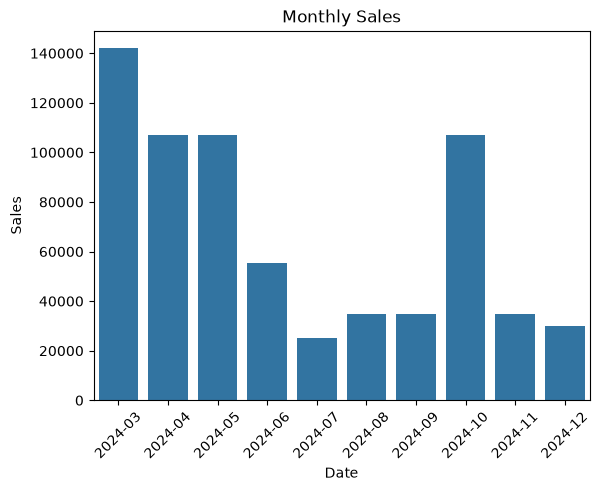

In [14]:
monthly_sales = data.groupby(
    data['Date'].dt.to_period('M')
)['Sales'].sum()
sns.barplot(
    x = monthly_sales.index,
    y = monthly_sales.values
)
plt.title('Monthly Sales')
plt.ylabel('Sales')
plt.xlabel('Date')
plt.xticks(rotation=45)
plt.show()

### Show the top 10 products by sales.

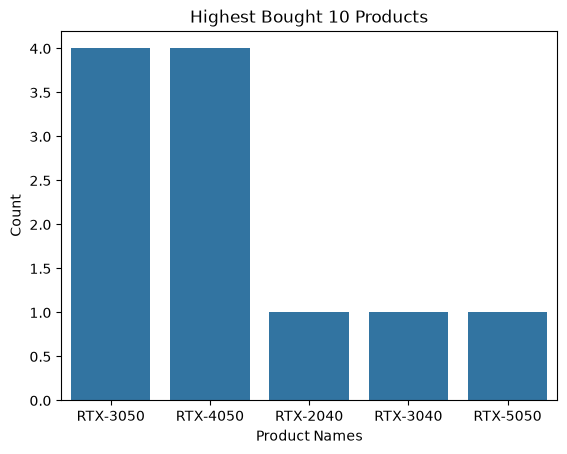

In [15]:
temp = data.groupby('Product')['Sales'].count()
temp = temp.sort_values(ascending=False)
res = temp.head(10)
sns.barplot(
    x = res.index,
    y = res.values
)
plt.xlabel('Product Names')
plt.ylabel('Count')
plt.title('Highest Bought 10 Products')
plt.show()

### Compare sales across different categories.

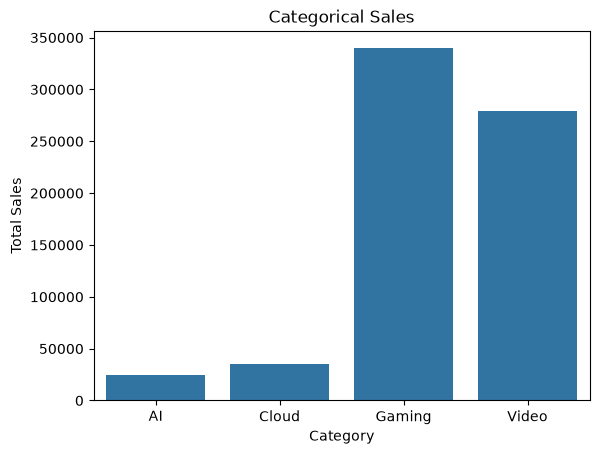

In [11]:
temp = data.groupby('Category')['Sales'].sum()
sns.barplot(
    x = temp.index,
    y = temp.values
)
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.title('Categorical Sales')
plt.show()

### Show sales distribution.

Index(['AI', 'Cloud', 'Gaming', 'Video'], dtype='str', name='Category')
[ 25000  34999 339495 278997]


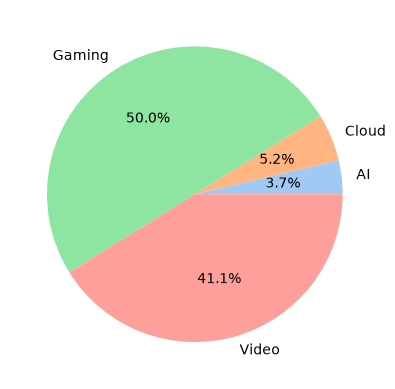

In [12]:
color = sns.color_palette('pastel')
temp = data.groupby('Category')['Sales'].sum()
x = temp.index
y = temp.values
print(x)
print(y)
plt.pie(x = y,labels = x,colors=color,autopct='%1.1f%%')

### Identify the best-performing month.

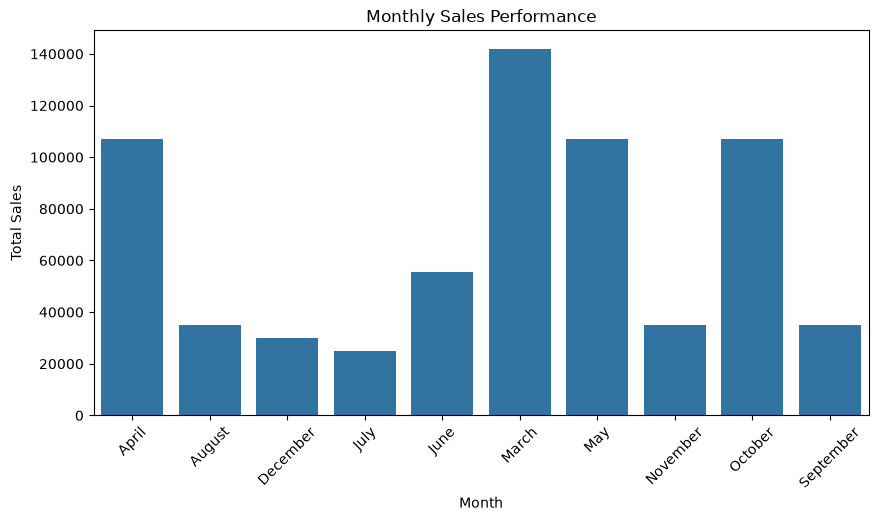

In [16]:
data['Month'] = data['Date'].dt.month_name()
monthly_sales = data.groupby('Month', as_index=False)['Sales'].sum()
plt.figure(figsize=(10, 5))
sns.barplot(
    data=monthly_sales,
    x='Month',
    y='Sales'
)
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Monthly Sales Performance')
plt.xticks(rotation=45)
plt.show()